# Notebook 6: Machine Learning — NIFTY 50 Market Direction Prediction

**Project:** Exploratory Data Analysis of NIFTY 50 Futures and Options Market

**Input:** Verified ML exports produced by Notebook 5 in `data/ml/`

**Task:** Three-class classification of the next observed session's direction.

## Objective

Train, compare, tune, evaluate and explain classification models using engineered Futures, Call Options (CE), and Put Options (PE) market features.

The target classes are:

- `-1 = Down`
- `0 = Sideways`
- `1 = Up`

The target is based on the derivatives-implied underlying-value proxy constructed from the supplied datasets. It is not an independently verified official NIFTY 50 spot-index closing-price series.

## Experimental Principles

1. Preserve chronological order; never randomly shuffle observations.
2. Use the training partition for cross-validation and hyperparameter search.
3. Purge training observations whose target dates reach the validation fold.
4. Use the validation partition for model selection.
5. Use the test partition once for final evaluation after fixing the model and hyperparameters.
6. Fit imputation and scaling inside model pipelines.
7. Report Macro F1 and Balanced Accuracy alongside class-wise Precision, Recall and Confusion Matrices.
8. Treat the results as academic research, not trading recommendations.

**Important:** This notebook does not create new labels or add external datasets. It consumes the Parquet files and metadata exported by Notebook 5.

## Recorded Experiment Snapshot

The executed run contains **775 labelled observations** and **43 predictor features**, split chronologically into 541 training, 115 validation and 117 test observations. The selected estimator was **Extra Trees**.

| Final test metric | Recorded result |
|---|---:|
| Accuracy | 0.3846 |
| Balanced accuracy | 0.3227 |
| Macro precision | 0.3223 |
| Macro recall | 0.3227 |
| Macro F1 | 0.3224 |
| Log loss | 1.0262 |

These are the recorded outputs from the completed execution embedded in this notebook. The final conclusion discusses their limitations and does not interpret them as evidence of a profitable trading strategy.


## 1. Project Setup and Configuration

This section imports the required libraries, fixes random seeds, locates the project repository and prepares output directories.

The notebook uses scikit-learn for model development and evaluation. XGBoost is optional; the notebook will continue with scikit-learn models if it is unavailable.

In [1]:
# ============================================
# 1.1 IMPORT LIBRARIES
# ============================================

import json
import random
import warnings
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

import sklearn

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Baseline and classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)

# Cross-validation and hyperparameter optimization
from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
    log_loss,
)

# Feature importance
from sklearn.inspection import permutation_importance

# Class weighting
from sklearn.utils.class_weight import compute_sample_weight

# Model saving
import joblib

# Warnings and display settings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.4f}"
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("Imports completed successfully.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Imports completed successfully.
Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1


In [2]:
# ============================================
# 1.2 OPTIONAL XGBOOST DETECTION
# ============================================

try:
    from xgboost import XGBClassifier

    XGBOOST_AVAILABLE = True

    import xgboost

    print("XGBoost available:", xgboost.__version__)

except ImportError:

    XGBClassifier = None
    XGBOOST_AVAILABLE = False

    print(
        "XGBoost is not installed. "
        "Scikit-learn models will still be used."
    )

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/yashraj/Projects/nifty50-FnO-eda/.venv/lib/python3.15/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <09B43001-8527-34F6-AAE4-B97DA8A6CBC0> /Users/yashraj/Projects/nifty50-FnO-eda/.venv/lib/python3.15/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/home

In [ ]:
# ============================================
# 1.3 LOCATE PROJECT ROOT AND CONFIGURE PATHS
# ============================================

current_dir = Path.cwd()

root_candidates = [
    current_dir,
    *current_dir.parents
]

PROJECT_ROOT = next(
    (
        p for p in root_candidates
        if (
            (p / "data" / "ml").is_dir()
            and (p / "notebooks").is_dir()
        )
    ),
    None
)

if PROJECT_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the repository root. "
        "Open this notebook from the project, "
        "or update PROJECT_ROOT manually."
    )

# Input directory
ML_DATA_DIR = PROJECT_ROOT / "data" / "ml"

# Output directories
MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "saved_models"
)

EVALUATION_DIR = (
    PROJECT_ROOT
    / "models"
    / "evaluation"
    / "notebook_06"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Target configuration
RANDOM_STATE = 42

RAW_CLASS_LABELS = [-1, 0, 1]

ENCODED_CLASS_LABELS = [0, 1, 2]

CLASS_NAMES = {
    0: "Down",
    1: "Sideways",
    2: "Up"
}

RAW_TO_ENCODED = {
    -1: 0,
     0: 1,
     1: 2
}

ENCODED_TO_RAW = {
    value: key
    for key, value in RAW_TO_ENCODED.items()
}

PRIMARY_METRIC = "macro_f1"

print("Project root:", PROJECT_ROOT)
print("ML input directory:", ML_DATA_DIR)
print("Model directory:", MODEL_DIR)
print("Evaluation directory:", EVALUATION_DIR)

Project root: /home/yashraj/nifty50-FnO-eda
ML input directory: /home/yashraj/nifty50-FnO-eda/data/ml
Model directory: /home/yashraj/nifty50-FnO-eda/models/saved_models
Evaluation directory: /home/yashraj/nifty50-FnO-eda/models/evaluation/notebook_06


In [ ]:
# ============================================
# 1.4 VERIFY REQUIRED NOTEBOOK 5 EXPORTS
# ============================================

required_files = [
    "train_dataset.parquet",
    "validation_dataset.parquet",
    "test_dataset.parquet",
    "full_ml_dataset.parquet",
    "feature_columns.json",
    "ml_metadata.json",
]

missing_files = [
    name
    for name in required_files
    if not (ML_DATA_DIR / name).is_file()
]

for name in required_files:

    path = ML_DATA_DIR / name

    if path.is_file():

        print(f"[FOUND] {name}")

    else:

        print(f"[MISSING] {name}")

if missing_files:

    raise FileNotFoundError(
        f"Missing Notebook 5 exports: {missing_files}"
    )

print("\nAll required inputs are present.")

[FOUND] train_dataset.parquet
[FOUND] validation_dataset.parquet
[FOUND] test_dataset.parquet
[FOUND] full_ml_dataset.parquet
[FOUND] feature_columns.json
[FOUND] ml_metadata.json

All required inputs are present.


## 2. Load and Validate the ML Datasets

The training, validation and test partitions are loaded exactly as exported by Notebook 5.

`Date` and `Target_Date` are retained for temporal auditing but are never used as predictors.

The target remains in its original `-1/0/1` form in the exported files and is encoded to `0/1/2` only for model compatibility.

In [ ]:
# ============================================
# 2.1 LOAD PARQUET DATASETS AND JSON METADATA
# ============================================

train_df = pd.read_parquet(
    ML_DATA_DIR / "train_dataset.parquet"
)

validation_df = pd.read_parquet(
    ML_DATA_DIR / "validation_dataset.parquet"
)

test_df = pd.read_parquet(
    ML_DATA_DIR / "test_dataset.parquet"
)

full_df = pd.read_parquet(
    ML_DATA_DIR / "full_ml_dataset.parquet"
)

# Load feature metadata
with open(
    ML_DATA_DIR / "feature_columns.json",
    "r",
    encoding="utf-8"
) as f:

    feature_metadata = json.load(f)

# Load ML metadata
with open(
    ML_DATA_DIR / "ml_metadata.json",
    "r",
    encoding="utf-8"
) as f:

    ml_metadata = json.load(f)

# Extract feature names
if isinstance(feature_metadata, dict):

    feature_columns = feature_metadata.get(
        "feature_columns",
        []
    )

else:

    feature_columns = feature_metadata

if not feature_columns:

    raise ValueError(
        "feature_columns.json does not contain "
        "a non-empty feature_columns list."
    )

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Testing:", test_df.shape)
print("Full labelled dataset:", full_df.shape)

print(
    "Number of declared features:",
    len(feature_columns)
)

print(
    "Target metadata:",
    ml_metadata.get(
        "target_mapping",
        "Not specified"
    )
)

Training: (541, 46)
Validation: (115, 46)
Testing: (117, 46)
Full labelled dataset: (775, 46)
Number of declared features: 43
Target metadata: {'-1': 'Down', '0': 'Sideways', '1': 'Up'}


In [ ]:
# ============================================
# 2.2 VALIDATE SCHEMA, TYPES, CHRONOLOGY
# ============================================

required_metadata_columns = {
    "Date",
    "Target_Date",
    "Target_Direction"
}

datasets = {
    "train": train_df,
    "validation": validation_df,
    "test": test_df,
    "full": full_df
}

for split_name, frame in datasets.items():

    # Check required columns
    missing = required_metadata_columns.difference(
        frame.columns
    )

    if missing:

        raise ValueError(
            f"{split_name} dataset is missing columns: "
            f"{sorted(missing)}"
        )

    # Check feature columns
    missing_features = set(
        feature_columns
    ).difference(frame.columns)

    if missing_features:

        raise ValueError(
            f"{split_name} dataset is missing features: "
            f"{sorted(missing_features)}"
        )

    # Convert date and target columns
    frame["Date"] = pd.to_datetime(
        frame["Date"],
        errors="coerce"
    )

    frame["Target_Date"] = pd.to_datetime(
        frame["Target_Date"],
        errors="coerce"
    )

    frame["Target_Direction"] = pd.to_numeric(
        frame["Target_Direction"],
        errors="coerce"
    )

    # Missing values in essential columns
    if frame[
        [
            "Date",
            "Target_Date",
            "Target_Direction"
        ]
    ].isna().any().any():

        raise ValueError(
            f"{split_name} contains missing "
            "dates or target labels."
        )

    # Duplicate dates
    if frame["Date"].duplicated().any():

        raise ValueError(
            f"{split_name} contains duplicate observation dates."
        )

    # Chronological order
    if not frame["Date"].is_monotonic_increasing:

        raise ValueError(
            f"{split_name} is not sorted chronologically."
        )

    # Target must be after feature date
    if not (
        frame["Target_Date"] > frame["Date"]
    ).all():

        raise ValueError(
            f"{split_name} contains an invalid target date."
        )

    # Target labels
    observed_classes = set(
        frame["Target_Direction"].astype(int).unique()
    )

    if not observed_classes.issubset(
        set(RAW_CLASS_LABELS)
    ):

        raise ValueError(
            f"{split_name} contains unexpected target classes."
        )

# Prevent target and metadata leakage
forbidden_predictors = {
    "Date",
    "Target_Date",
    "Next_Session_Return",
    "Target_Direction",
    "Target_Label",
    "Valid_Next_Session_Target"
}

leakage_features = (
    forbidden_predictors.intersection(
        feature_columns
    )
)

if leakage_features:

    raise ValueError(
        "Leakage or metadata columns found in features: "
        f"{sorted(leakage_features)}"
    )

# Check identical feature order
for split_name, frame in {
    "train": train_df,
    "validation": validation_df,
    "test": test_df
}.items():

    actual_features = [
        c for c in frame.columns
        if c not in required_metadata_columns
    ]

    if actual_features != feature_columns:

        raise ValueError(
            f"{split_name} feature order/schema "
            "differs from feature_columns.json"
        )

# Chronological split checks
assert (
    train_df["Date"].max()
    < validation_df["Date"].min()
)

assert (
    validation_df["Date"].max()
    < test_df["Date"].min()
)

# Target-date purging checks
assert (
    train_df["Target_Date"].max()
    < validation_df["Date"].min()
)

assert (
    validation_df["Target_Date"].max()
    < test_df["Date"].min()
)

print(
    "Schema, target classes, chronology, "
    "leakage and purged split-boundary checks passed."
)

Schema, target classes, chronology, leakage and purged split-boundary checks passed.


In [ ]:
# ============================================
# 2.3 PREPARE NUMERIC PREDICTOR MATRICES
# ============================================

# Convert predictors to numeric.
# Replace infinite values with NaN.
# Imputation will happen later inside model pipelines.

def make_feature_matrix(frame, columns):

    matrix = frame[columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    return matrix.replace(
        [np.inf, -np.inf],
        np.nan
    )


X_train = make_feature_matrix(
    train_df,
    feature_columns
)

X_validation = make_feature_matrix(
    validation_df,
    feature_columns
)

X_test = make_feature_matrix(
    test_df,
    feature_columns
)

# Original target labels
y_train_raw = (
    train_df["Target_Direction"]
    .astype(int)
    .copy()
)

y_validation_raw = (
    validation_df["Target_Direction"]
    .astype(int)
    .copy()
)

y_test_raw = (
    test_df["Target_Direction"]
    .astype(int)
    .copy()
)

# Encode labels for model compatibility
y_train = (
    y_train_raw
    .map(RAW_TO_ENCODED)
    .astype(int)
)

y_validation = (
    y_validation_raw
    .map(RAW_TO_ENCODED)
    .astype(int)
)

y_test = (
    y_test_raw
    .map(RAW_TO_ENCODED)
    .astype(int)
)

print("Predictor matrix shapes:")

print(
    "Training:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_validation.shape,
    y_validation.shape
)

print(
    "Testing:",
    X_test.shape,
    y_test.shape
)

print("\nEncoded class mapping:")
print(CLASS_NAMES)

Predictor matrix shapes:
Training: (541, 43) (541,)
Validation: (115, 43) (115,)
Testing: (117, 43) (117,)

Encoded class mapping:
{0: 'Down', 1: 'Sideways', 2: 'Up'}


In [ ]:
# ============================================
# 2.4 DATA QUALITY AND CLASS AVAILABILITY
# ============================================

if len(train_df) < 60:

    raise ValueError(
        "Training set is too small for the planned "
        "time-series experiments (<60 rows)."
    )

if X_train.shape[1] == 0:

    raise ValueError(
        "No model features are available."
    )

# Verify all three classes exist in training data
train_classes = set(
    y_train.unique()
)

if train_classes != set(ENCODED_CLASS_LABELS):

    raise ValueError(
        "Training partition does not contain all three classes. "
        f"Observed classes: {sorted(train_classes)}. "
        "Review the target distribution and chronological split."
    )

# Check missing values
print(
    "Missing predictor values (training):",
    int(X_train.isna().sum().sum())
)

print(
    "Missing predictor values (validation):",
    int(X_validation.isna().sum().sum())
)

print(
    "Missing predictor values (testing):",
    int(X_test.isna().sum().sum())
)

print("\nAll three target classes are present in training.")

print(
    "\nTarget proxy limitation:",
    ml_metadata.get(
        "underlying_source_limitation",
        "Check Notebook 5 metadata."
    )
)

Missing predictor values (training): 1422
Missing predictor values (validation): 0
Missing predictor values (testing): 0

All three target classes are present in training.

Target proxy limitation: Derivatives-implied proxy, not an independent official NIFTY 50 spot close series; missing observations are not imputed


## 3. Target Distribution and Feature Diagnostics

Before fitting machine learning models, we inspect the target class distribution and predictor quality.

Class imbalance can make ordinary accuracy misleading. We therefore examine the proportion of Down, Sideways and Up observations across all chronological partitions.

Missing predictor values are not filled manually. Imputation will be performed inside the machine learning pipelines, ensuring that imputation statistics are learned only from the corresponding training observations.

,Dataset,Class,Raw_Label,Count,Percentage
0,Training,Down,-1,214,39.5564
1,Training,Sideways,0,67,12.3845
2,Training,Up,1,260,48.0591
3,Validation,Down,-1,51,44.3478
4,Validation,Sideways,0,13,11.3043
5,Validation,Up,1,51,44.3478
6,Testing,Down,-1,57,48.7179
7,Testing,Sideways,0,13,11.1111
8,Testing,Up,1,47,40.1709


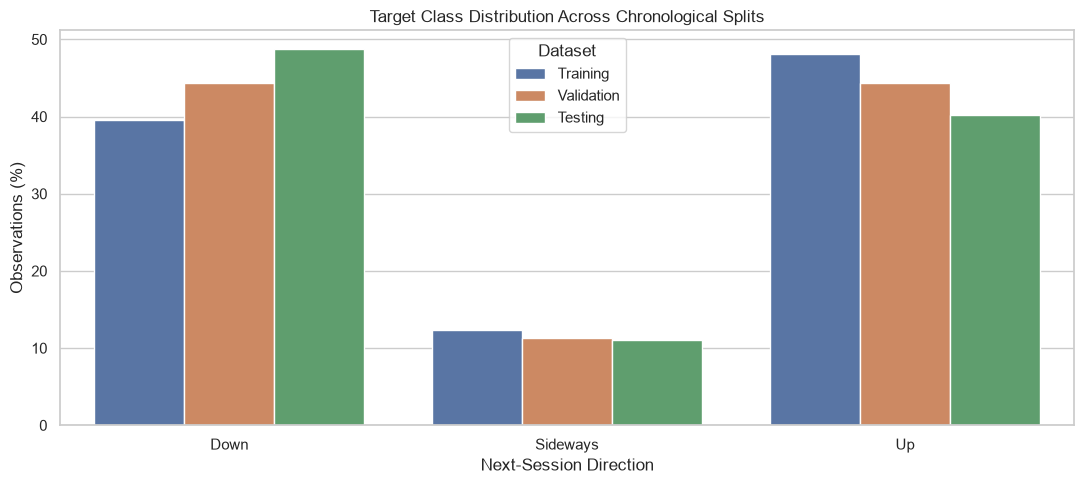

In [ ]:
# ============================================
# 3.1 TARGET DISTRIBUTION ACROSS PARTITIONS
# ============================================

def distribution_table(series, name):

    counts = series.value_counts().reindex(
        RAW_CLASS_LABELS,
        fill_value=0
    )

    return pd.DataFrame({
        "Dataset": name,
        "Class": ["Down", "Sideways", "Up"],
        "Raw_Label": RAW_CLASS_LABELS,
        "Count": counts.values,
        "Percentage": (
            counts / len(series) * 100
        ).values
    })


class_distribution = pd.concat([
    distribution_table(y_train_raw, "Training"),
    distribution_table(y_validation_raw, "Validation"),
    distribution_table(y_test_raw, "Testing"),
], ignore_index=True)

display(class_distribution)


# Visualize class proportions
plt.figure(figsize=(11, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Percentage",
    hue="Dataset"
)

plt.title(
    "Target Class Distribution Across Chronological Splits"
)

plt.ylabel("Observations (%)")
plt.xlabel("Next-Session Direction")

plt.tight_layout()
plt.show()

,Train_Missing_Count,Train_Missing_Percentage,Validation_Missing_Percentage,Test_Missing_Percentage
NIFTY_Return_Lag_10,181,33.4566,0.0000,0.0000
NIFTY_Return_Lag_1,175,32.3475,0.0000,0.0000
NIFTY_Return_Lag_2,173,31.9778,0.0000,0.0000
NIFTY_Return_Lag_3,163,30.1294,0.0000,0.0000
NIFTY_Return_Lag_5,159,29.3900,0.0000,0.0000
NIFTY_Momentum_10D,107,19.7782,0.0000,0.0000
NIFTY_Momentum_3D,106,19.5933,0.0000,0.0000
NIFTY_Return,105,19.4085,0.0000,0.0000
NIFTY_Momentum_5D,90,16.6359,0.0000,0.0000
CE_Relative_Volume_20D,12,2.2181,0.0000,0.0000


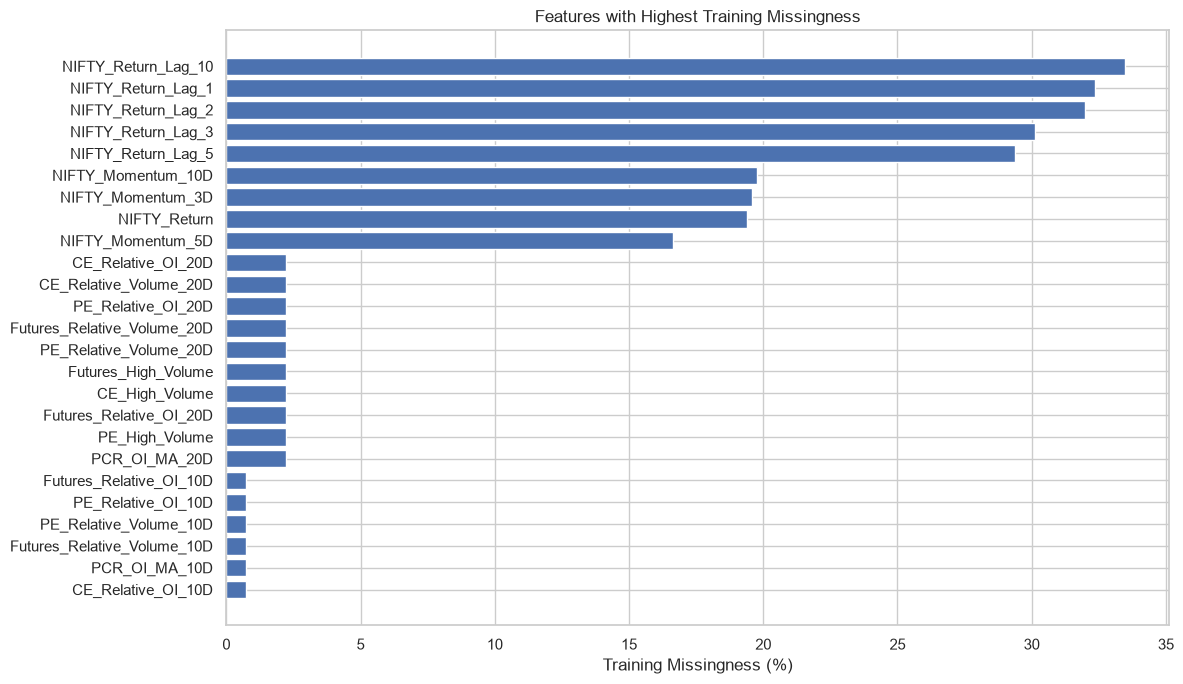

In [ ]:
# ============================================
# 3.2 TRAINING FEATURE MISSINGNESS AUDIT
# ============================================

missing_report = pd.DataFrame({

    "Train_Missing_Count": X_train.isna().sum(),

    "Train_Missing_Percentage":
        X_train.isna().mean() * 100,

    "Validation_Missing_Percentage":
        X_validation.isna().mean() * 100,

    "Test_Missing_Percentage":
        X_test.isna().mean() * 100

}).sort_values(
    "Train_Missing_Percentage",
    ascending=False
)

display(missing_report.head(25))


# Identify features entirely missing in training
all_missing_train = missing_report.index[
    missing_report["Train_Missing_Percentage"] >= 100
].tolist()

if all_missing_train:

    raise ValueError(
        "Features entirely missing in training data: "
        f"{all_missing_train}. "
        "Review Notebook 5 feature selection before proceeding."
    )


# Plot features with missing values
plt.figure(figsize=(12, 7))

plot_missing = (
    missing_report[
        missing_report["Train_Missing_Percentage"] > 0
    ]
    .head(25)
    .sort_values("Train_Missing_Percentage")
)

if not plot_missing.empty:

    plt.barh(
        plot_missing.index,
        plot_missing["Train_Missing_Percentage"]
    )

    plt.xlabel("Training Missingness (%)")
    plt.title("Features with Highest Training Missingness")

    plt.tight_layout()
    plt.show()

else:

    print(
        "No missing predictor values in the training partition."
    )

In [ ]:
# ============================================
# 3.3 DESCRIPTIVE FEATURE STATISTICS
# ============================================

feature_statistics = (
    X_train.describe()
    .T
    .sort_values("std", ascending=False)
)

display(
    feature_statistics.head(25)
)

,count,mean,std,min,25%,50%,75%,max
NIFTY_Momentum_10D,434.0000,0.5464,2.3276,-6.3606,-1.2496,0.5913,2.0911,8.6135
NIFTY_Momentum_5D,451.0000,0.2906,1.8219,-5.6481,-0.8367,0.1899,1.5038,7.8024
NIFTY_Momentum_3D,435.0000,0.1927,1.3689,-4.2689,-0.6897,0.2323,1.0685,4.6343
PE_Volume_Pct_Change,540.0000,0.5341,1.3264,-0.9836,-0.1046,0.2254,0.8187,9.3412
CE_Volume_Pct_Change,540.0000,0.5025,1.2423,-0.9797,-0.1135,0.2109,0.7929,9.0759
NIFTY_Return_Lag_10,360.0000,0.0362,0.8219,-5.9294,-0.3976,0.0296,0.4443,3.8183
NIFTY_Return_Lag_5,382.0000,0.0823,0.8008,-5.9294,-0.3432,0.0952,0.4963,3.8183
PE_Relative_Volume_20D,529.0000,0.9885,0.7989,0.0427,0.4780,0.6654,1.0932,4.4095
NIFTY_Return,436.0000,0.0512,0.7838,-5.9294,-0.3559,0.0500,0.4735,3.8183
CE_Relative_Volume_20D,529.0000,0.9883,0.7745,0.0542,0.4949,0.6865,1.0863,3.9293


## 4. Evaluation Helpers and Baseline Models

A baseline establishes the minimum performance that more sophisticated models should improve upon.

We evaluate two simple classification strategies:

1. **Dummy Most Frequent:** Always predicts the most frequent class in the training dataset.
2. **Dummy Stratified:** Generates predictions according to the class proportions observed in the training dataset.

All models are evaluated using the same fixed three-class label set.

Macro F1 is the primary metric because it gives equal importance to the Down, Sideways and Up classes.

In [ ]:
# ============================================
# 4.1 DEFINE CONSISTENT EVALUATION FUNCTIONS
# ============================================

SCORING_LABELS = ENCODED_CLASS_LABELS


def calculate_metrics(y_true, y_pred, y_proba=None):

    result = {
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "Macro_Precision": precision_score(
            y_true,
            y_pred,
            labels=SCORING_LABELS,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_true,
            y_pred,
            labels=SCORING_LABELS,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true,
            y_pred,
            labels=SCORING_LABELS,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:
            result["Log_Loss"] = log_loss(
                y_true,
                y_proba,
                labels=SCORING_LABELS
            )

        except ValueError:
            result["Log_Loss"] = np.nan

    return result


def aligned_predict_proba(estimator, X):
    """
    Return predicted probabilities in fixed class order:
    [0 = Down, 1 = Sideways, 2 = Up].
    """

    if not hasattr(estimator, "predict_proba"):
        return None

    raw_probabilities = estimator.predict_proba(X)

    aligned = np.zeros(
        (len(X), len(ENCODED_CLASS_LABELS)),
        dtype=float
    )

    model_classes = estimator.classes_

    for j, class_label in enumerate(model_classes):

        aligned[:, int(class_label)] = (
            raw_probabilities[:, j]
        )

    row_sums = aligned.sum(
        axis=1,
        keepdims=True
    )

    aligned = np.divide(
        aligned,
        row_sums,
        out=np.zeros_like(aligned),
        where=row_sums > 0
    )

    return aligned


def evaluate_estimator(estimator, X, y, name):

    predictions = estimator.predict(X)

    probabilities = aligned_predict_proba(
        estimator,
        X
    )

    metrics = calculate_metrics(
        y,
        predictions,
        probabilities
    )

    metrics["Model"] = name

    return metrics, predictions, probabilities


# Primary cross-validation scoring metric
macro_f1_scorer = make_scorer(
    f1_score,
    labels=SCORING_LABELS,
    average="macro",
    zero_division=0
)

print("Evaluation functions defined successfully.")
print("Primary metric: Macro F1")

Evaluation functions defined successfully.
Primary metric: Macro F1


In [ ]:
# ============================================
# 4.2 FIT BASELINE CLASSIFIERS
# ============================================

baseline_models = {

    "Dummy Most Frequent": DummyClassifier(
        strategy="most_frequent"
    ),

    "Dummy Stratified": DummyClassifier(
        strategy="stratified",
        random_state=RANDOM_STATE
    )
}


baseline_results = []
baseline_fitted = {}

for name, estimator in baseline_models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            estimator
        )
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    metrics, predictions, probabilities = (
        evaluate_estimator(
            pipeline,
            X_validation,
            y_validation,
            name
        )
    )

    baseline_results.append(metrics)

    baseline_fitted[name] = pipeline


baseline_results_df = (
    pd.DataFrame(baseline_results)
    .set_index("Model")
    .sort_values(
        "Macro_F1",
        ascending=False
    )
)

display(baseline_results_df)

print(
    "Baseline evaluation completed."
)
print(
    "Advanced models must demonstrate improvement "
    "over these reference results."
)

Training Dummy Most Frequent...
Training Dummy Stratified...


,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss
Model,,,,,,
Dummy Stratified,0.3826,0.3067,0.3086,0.3067,0.3068,22.2530
Dummy Most Frequent,0.4435,0.3333,0.1478,0.3333,0.2048,20.0591


Baseline evaluation completed.
Advanced models must demonstrate improvement over these reference results.


## 5. Candidate Machine Learning Models

This section develops multiple classification models to identify patterns in the engineered market features.

The candidate models include:

1. Logistic Regression.
2. Random Forest.
3. Extra Trees.
4. Histogram-based Gradient Boosting.
5. XGBoost, if available.

All models use pipelines to ensure missing-value imputation is performed within the training process.

Standardization is applied to Logistic Regression because it is sensitive to feature scale. Tree-based models do not require standardization.

Class imbalance is addressed through class weights or balanced sample weights where supported.

The models are initially trained using the training partition and compared using the validation partition. This initial comparison is exploratory; final selection will happen after chronological cross-validation and hyperparameter tuning.

In [ ]:
# ============================================
# 5.1 BUILD MODEL PIPELINES
# ============================================

def make_pipeline(estimator, scale=False):

    steps = [
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]

    if scale:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            estimator
        )
    )

    return Pipeline(steps)


candidate_pipelines = {

    "Logistic Regression": make_pipeline(
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        scale=True
    ),

    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            max_features="sqrt",
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),

    "Extra Trees": make_pipeline(
        ExtraTreesClassifier(
            n_estimators=200,
            max_features="sqrt",
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),

    "Hist Gradient Boosting": make_pipeline(
        HistGradientBoostingClassifier(
            learning_rate=0.06,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=0.5,
            random_state=RANDOM_STATE
        )
    )
}


# Add XGBoost only when available
if XGBOOST_AVAILABLE:

    candidate_pipelines["XGBoost"] = make_pipeline(
        XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            tree_method="hist",
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=2.0,
            random_state=RANDOM_STATE,
            n_jobs=2
        )
    )


print("Candidate models created:\n")

for name in candidate_pipelines:

    print("-", name)

Candidate models created:

- Logistic Regression
- Random Forest
- Extra Trees
- Hist Gradient Boosting
- XGBoost


In [ ]:
# ============================================
# 5.2 INITIAL MODEL TRAINING AND COMPARISON
# ============================================

initial_results = []
initial_fitted_models = {}

for name, pipeline in candidate_pipelines.items():

    print(f"\nFitting {name}...")

    fitted = clone(pipeline)

    # Balanced sample weights for models that
    # do not directly expose class_weight.
    if name in {
        "Hist Gradient Boosting",
        "XGBoost"
    }:

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        fitted.fit(
            X_train,
            y_train,
            model__sample_weight=sample_weights
        )

    else:

        fitted.fit(
            X_train,
            y_train
        )

    metrics, predictions, probabilities = (
        evaluate_estimator(
            fitted,
            X_validation,
            y_validation,
            name
        )
    )

    initial_results.append(metrics)

    initial_fitted_models[name] = fitted


initial_results_df = (
    pd.DataFrame(initial_results)
    .set_index("Model")
    .sort_values(
        "Macro_F1",
        ascending=False
    )
)

display(initial_results_df)

print(
    "\nInitial validation comparison completed."
)

print(
    "Hyperparameter tuning follows in Section 6."
)


Fitting Logistic Regression...



Fitting Random Forest...

Fitting Extra Trees...

Fitting Hist Gradient Boosting...

Fitting XGBoost...


,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss
Model,,,,,,
Extra Trees,0.4609,0.3655,0.4216,0.3655,0.3653,0.9777
Random Forest,0.4870,0.3660,0.3305,0.3660,0.3403,0.9957
Hist Gradient Boosting,0.3913,0.3132,0.3248,0.3132,0.3095,1.3578
XGBoost,0.3739,0.3002,0.2996,0.3002,0.2990,1.0934
Logistic Regression,0.2870,0.3303,0.3085,0.3303,0.2705,1.1729



Initial validation comparison completed.
Hyperparameter tuning follows in Section 6.


## 6. Purged Time-Series Cross-Validation and Hyperparameter Tuning

Hyperparameter search is restricted to the training partition. A chronological `TimeSeriesSplit` creates expanding training windows. Because each row's label refers to a future `Target_Date`, each fold additionally purges training rows whose target date is on or after the first date in that fold's validation window.

This is stricter than applying ordinary shuffled cross-validation. The number of usable folds depends on whether each training fold contains all three classes.

In [ ]:
# 6.1 Construct purged chronological CV folds
N_CV_SPLITS = 3
base_tscv = TimeSeriesSplit(n_splits=N_CV_SPLITS)
cv_splits = []
cv_fold_summary = []

train_dates = train_df["Date"].reset_index(drop=True)
train_target_dates = train_df["Target_Date"].reset_index(drop=True)
y_train_array = y_train.reset_index(drop=True)

for fold_number, (candidate_train_idx, fold_valid_idx) in enumerate(base_tscv.split(X_train), start=1):
    fold_valid_start = train_dates.iloc[fold_valid_idx[0]]
    purged_train_idx = candidate_train_idx[
        train_target_dates.iloc[candidate_train_idx].to_numpy() < np.datetime64(fold_valid_start)
    ]

    fold_train_classes = set(y_train_array.iloc[purged_train_idx].unique())
    if len(purged_train_idx) == 0 or fold_train_classes != set(ENCODED_CLASS_LABELS):
        print(f"Skipping fold {fold_number}: insufficient purged training rows or missing classes.")
        continue

    cv_splits.append((purged_train_idx, fold_valid_idx))
    cv_fold_summary.append({
        "Fold": fold_number,
        "Train_Rows": len(purged_train_idx),
        "Validation_Rows": len(fold_valid_idx),
        "Train_End": train_dates.iloc[purged_train_idx].max(),
        "Validation_Start": fold_valid_start,
        "Max_Train_Target_Date": train_target_dates.iloc[purged_train_idx].max(),
        "Purged_Rows": len(candidate_train_idx) - len(purged_train_idx),
    })

cv_fold_summary_df = pd.DataFrame(cv_fold_summary)
display(cv_fold_summary_df)

if len(cv_splits) < 2:
    raise ValueError(
        "Fewer than two valid purged CV folds contain all three classes. "
        "Do not proceed with hyperparameter search; inspect the training class chronology "
        "or reduce N_CV_SPLITS while retaining temporal purging."
    )

print(f"Using {len(cv_splits)} valid purged chronological CV folds.")

,Fold,Train_Rows,Validation_Rows,Train_End,Validation_Start,Max_Train_Target_Date,Purged_Rows
0,1,135,135,2023-08-30,2023-09-01,2023-08-31,1
1,2,270,135,2024-05-29,2024-05-31,2024-05-30,1
2,3,405,135,2025-03-18,2025-03-20,2025-03-19,1


Using 3 valid purged chronological CV folds.


In [ ]:
# 6.2 Define compact search spaces
search_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1.0, 10.0, 50.0],
        "model__class_weight": ["balanced", None],
    },
    "Random Forest": {
        "model__n_estimators": [120, 200, 300],
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": ["sqrt", 0.7],
        "model__class_weight": ["balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "model__n_estimators": [120, 200, 300],
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": ["sqrt", 0.7],
        "model__class_weight": ["balanced", "balanced_subsample"],
    },
    "Hist Gradient Boosting": {
        "model__learning_rate": [0.025, 0.05, 0.08, 0.12],
        "model__max_iter": [100, 175, 250],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__l2_regularization": [0.0, 0.5, 1.0, 3.0],
    },
}

if XGBOOST_AVAILABLE:
    search_spaces["XGBoost"] = {
        "model__n_estimators": [120, 200, 300],
        "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.025, 0.05, 0.08, 0.12],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1.0, 3.0, 6.0],
    }

print("Search spaces defined for:", list(search_spaces))

Search spaces defined for: ['Logistic Regression', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting', 'XGBoost']


In [ ]:
# 6.3 Run randomized hyperparameter search on training data only
N_ITER_SEARCH = 5
search_objects = {}
tuning_summary = []

for name, pipeline in candidate_pipelines.items():
    print(f"\nTuning {name}...")
    search = RandomizedSearchCV(
        estimator=clone(pipeline),
        param_distributions=search_spaces[name],
        n_iter=N_ITER_SEARCH,
        scoring=macro_f1_scorer,
        cv=cv_splits,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        pre_dispatch=1,
        verbose=1,
        error_score="raise",
        return_train_score=True,
    )

    fit_kwargs = {}
    if name in {"Hist Gradient Boosting", "XGBoost"}:
        fit_kwargs["model__sample_weight"] = compute_sample_weight(class_weight="balanced", y=y_train)

    search.fit(X_train, y_train, **fit_kwargs)
    search_objects[name] = search
    tuning_summary.append({
        "Model": name,
        "Best_CV_Macro_F1": search.best_score_,
        "Best_Params": search.best_params_,
        "Best_Estimator": search.best_estimator_,
    })
    print("Best CV macro F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

print("\nHyperparameter tuning completed.")


Tuning Logistic Regression...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV macro F1: 0.3102
Best parameters: {'model__class_weight': None, 'model__C': 10.0}

Tuning Random Forest...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV macro F1: 0.2984
Best parameters: {'model__n_estimators': 120, 'model__min_samples_split': 5, 'model__min_samples_leaf': 8, 'model__max_features': 'sqrt', 'model__max_depth': 6, 'model__class_weight': 'balanced'}

Tuning Extra Trees...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV macro F1: 0.3216
Best parameters: {'model__n_estimators': 120, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced_subsample'}

Tuning Hist Gradient Boosting...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV macro F1: 0.3081
Best parameters: {'model__max_leaf_nodes': 7, 'model__max_iter': 100, 'model__l

In [ ]:
# 6.4 Summarize cross-validation results
cv_results_rows = []
for name, search in search_objects.items():
    result = search.cv_results_
    best_index = search.best_index_
    cv_results_rows.append({
        "Model": name,
        "Best_CV_Macro_F1": float(search.best_score_),
        "CV_Std": float(result["std_test_score"][best_index]),
        "Mean_Train_Macro_F1": float(result["mean_train_score"][best_index]),
        "Best_Params": json.dumps(search.best_params_, default=str),
    })

cv_results_summary = pd.DataFrame(cv_results_rows).sort_values("Best_CV_Macro_F1", ascending=False)
display(cv_results_summary)
print("CV results use only the training partition and purged chronological folds.")

,Model,Best_CV_Macro_F1,CV_Std,Mean_Train_Macro_F1,Best_Params
2,Extra Trees,0.3216,0.0497,0.9984,"{""model__n_estimators"": 120, ""model__min_sampl..."
0,Logistic Regression,0.3102,0.0366,0.5724,"{""model__class_weight"": null, ""model__C"": 10.0}"
3,Hist Gradient Boosting,0.3081,0.0391,0.9885,"{""model__max_leaf_nodes"": 7, ""model__max_iter""..."
1,Random Forest,0.2984,0.0359,0.7607,"{""model__n_estimators"": 120, ""model__min_sampl..."
4,XGBoost,0.2902,0.0130,0.9477,"{""model__subsample"": 0.85, ""model__reg_lambda""..."


CV results use only the training partition and purged chronological folds.


## 7. Validation-Based Model Selection

The tuned estimators are now evaluated on the separate validation partition. Model selection is based primarily on validation Macro F1, with Balanced Accuracy as a secondary diagnostic. The test partition remains untouched.

In [ ]:
# 7.1 Evaluate tuned models on validation data

validation_results = []
validation_predictions = {}
validation_probabilities = {}

for name, search in search_objects.items():

    estimator = search.best_estimator_

    metrics, predictions, probabilities = evaluate_estimator(
        estimator,
        X_validation,
        y_validation,
        name
    )

    validation_results.append(metrics)
    validation_predictions[name] = predictions
    validation_probabilities[name] = probabilities


# Include baseline references in the same comparison table.
for name, estimator in baseline_fitted.items():

    metrics, predictions, probabilities = evaluate_estimator(
        estimator,
        X_validation,
        y_validation,
        name
    )

    validation_results.append(metrics)
    validation_predictions[name] = predictions
    validation_probabilities[name] = probabilities


validation_results_df = (
    pd.DataFrame(validation_results)
    .set_index("Model")
    .sort_values(
        ["Macro_F1", "Balanced_Accuracy"],
        ascending=False
    )
)

display(validation_results_df)

best_model_name = validation_results_df.index[0]

if best_model_name in search_objects:

    selected_estimator = search_objects[best_model_name].best_estimator_
    selected_model_type = "Tuned classifier"

else:

    selected_estimator = baseline_fitted[best_model_name]
    selected_model_type = "Baseline classifier"


print("Selected model:", best_model_name)
print("Selection type:", selected_model_type)
print("Selection criterion: validation Macro F1, then Balanced Accuracy.")

,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss
Model,,,,,,
Extra Trees,0.4696,0.3720,0.3699,0.3720,0.3704,0.9958
Random Forest,0.4000,0.3580,0.3583,0.3580,0.3502,1.0511
Hist Gradient Boosting,0.3739,0.3193,0.3181,0.3193,0.3177,1.0917
XGBoost,0.3826,0.3067,0.3205,0.3067,0.3115,1.0768
Dummy Stratified,0.3826,0.3067,0.3086,0.3067,0.3068,22.2530
Logistic Regression,0.4261,0.3203,0.2890,0.3203,0.2861,1.0507
Dummy Most Frequent,0.4435,0.3333,0.1478,0.3333,0.2048,20.0591


Selected model: Extra Trees
Selection type: Tuned classifier
Selection criterion: validation Macro F1, then Balanced Accuracy.


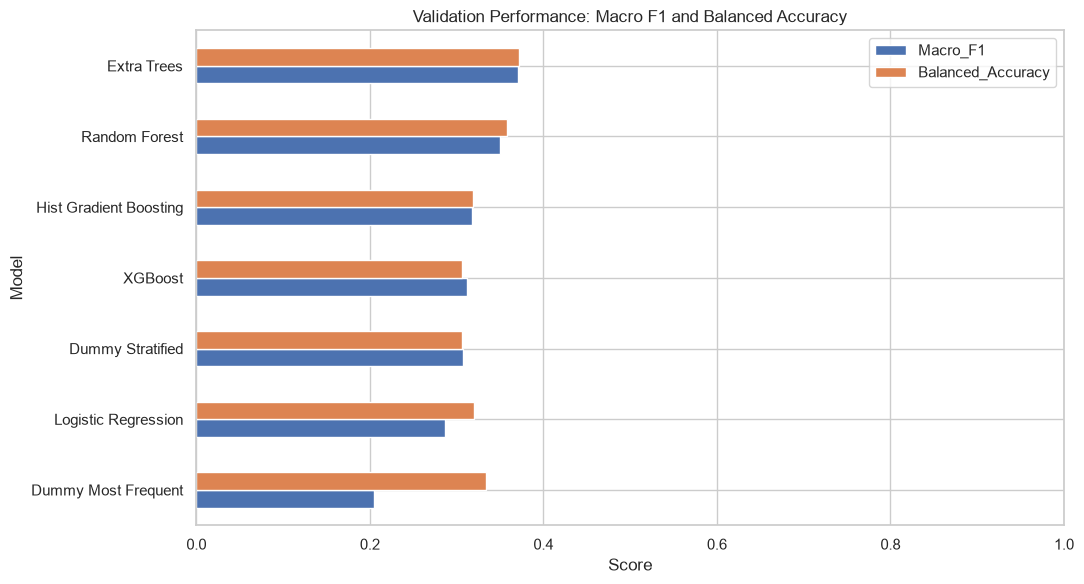

In [ ]:
# 7.2 Visualize validation Macro F1 and Balanced Accuracy

plot_metrics = validation_results_df[
    ["Macro_F1", "Balanced_Accuracy"]
].sort_values("Macro_F1")

plot_metrics.plot(
    kind="barh",
    figsize=(11, 6)
)

plt.title("Validation Performance: Macro F1 and Balanced Accuracy")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

        Down       0.52      0.53      0.52        51
    Sideways       0.10      0.08      0.09        13
          Up       0.49      0.51      0.50        51

    accuracy                           0.47       115
   macro avg       0.37      0.37      0.37       115
weighted avg       0.46      0.47      0.46       115



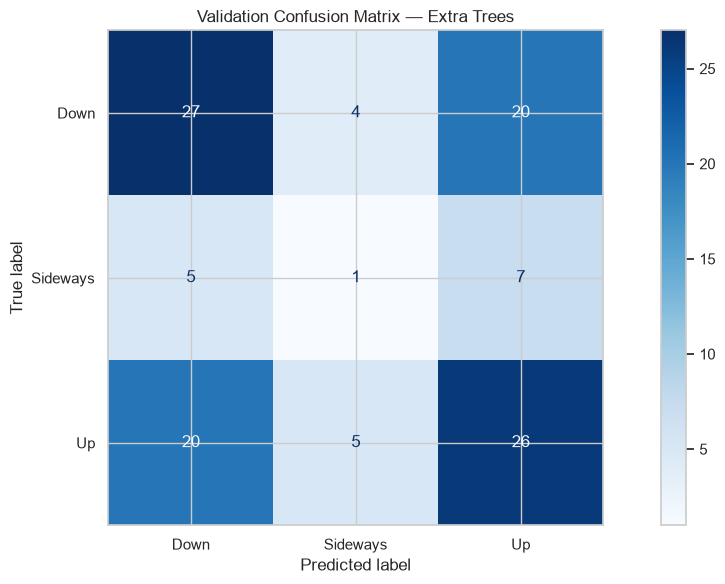

In [ ]:
# 7.3 Detailed validation report for the selected model

selected_validation_predictions = validation_predictions[best_model_name]

print(
    classification_report(
        y_validation,
        selected_validation_predictions,
        labels=ENCODED_CLASS_LABELS,
        target_names=[
            CLASS_NAMES[i]
            for i in ENCODED_CLASS_LABELS
        ],
        zero_division=0
    )
)


cm_validation = confusion_matrix(
    y_validation,
    selected_validation_predictions,
    labels=ENCODED_CLASS_LABELS
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_validation,
    display_labels=[
        CLASS_NAMES[i]
        for i in ENCODED_CLASS_LABELS
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Validation Confusion Matrix — {best_model_name}"
)

plt.tight_layout()
plt.show()

## 8. Final Model Refit and Untouched Test Evaluation

After selecting the model and its hyperparameters using training cross-validation and validation performance, refit the selected estimator on the combined training and validation observations. Then evaluate it on the test partition once. Do not change the model or its parameters based on test results.

In [ ]:
# 8.1 Refit selected model on training + validation

X_train_validation = pd.concat(
    [X_train, X_validation],
    axis=0
).reset_index(drop=True)

y_train_validation = pd.concat(
    [y_train, y_validation],
    axis=0
).reset_index(drop=True)

final_model = clone(selected_estimator)

# Recompute class-balanced sample weights only for models
# that were trained with sample weights.

if best_model_name in {
    "Hist Gradient Boosting",
    "XGBoost"
}:

    final_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_validation
    )

    final_model.fit(
        X_train_validation,
        y_train_validation,
        model__sample_weight=final_weights
    )

else:

    final_model.fit(
        X_train_validation,
        y_train_validation
    )


print("Final model refitted on train + validation.")
print("Final model:", best_model_name)
print("Refit observations:", len(X_train_validation))

Final model refitted on train + validation.
Final model: Extra Trees
Refit observations: 656


In [ ]:
# 8.2 One-time final test evaluation

test_metrics, y_test_pred, y_test_proba = evaluate_estimator(
    final_model,
    X_test,
    y_test,
    best_model_name
)

test_metrics_df = pd.DataFrame(
    [test_metrics]
).set_index("Model")

display(test_metrics_df)


print("Final test classification report:")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=ENCODED_CLASS_LABELS,
        target_names=[
            CLASS_NAMES[i]
            for i in ENCODED_CLASS_LABELS
        ],
        zero_division=0
    )
)

,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss
Model,,,,,,
Extra Trees,0.3846,0.3227,0.3223,0.3227,0.3224,1.0262


Final test classification report:
              precision    recall  f1-score   support

        Down       0.46      0.47      0.47        57
    Sideways       0.15      0.15      0.15        13
          Up       0.36      0.34      0.35        47

    accuracy                           0.38       117
   macro avg       0.32      0.32      0.32       117
weighted avg       0.38      0.38      0.38       117



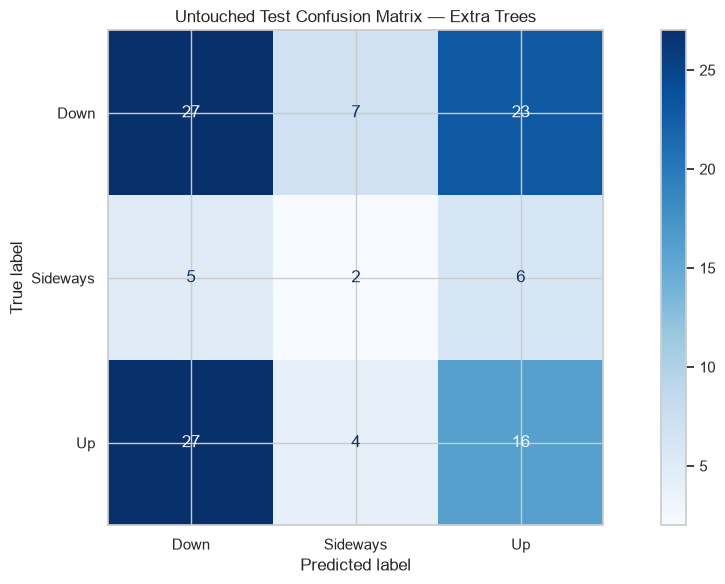

In [ ]:
# 8.3 Final test confusion matrix

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=ENCODED_CLASS_LABELS
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=[
        CLASS_NAMES[i]
        for i in ENCODED_CLASS_LABELS
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Untouched Test Confusion Matrix — {best_model_name}"
)

plt.tight_layout()
plt.show()

In [ ]:
# 8.4 Compare validation and final test metrics

validation_selected_metrics = validation_results_df.loc[
    best_model_name
]

comparison_rows = []

for metric in [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1"
]:

    comparison_rows.append({
        "Metric": metric,
        "Validation": float(
            validation_selected_metrics[metric]
        ),
        "Test": float(
            test_metrics[metric]
        ),
    })


validation_test_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Metric")
)

display(validation_test_comparison)

print(
    "A validation-to-test performance gap may indicate "
    "temporal distribution shift or overfitting."
)

,Validation,Test
Metric,,
Accuracy,0.4696,0.3846
Balanced_Accuracy,0.3720,0.3227
Macro_Precision,0.3699,0.3223
Macro_Recall,0.3720,0.3227
Macro_F1,0.3704,0.3224


A validation-to-test performance gap may indicate temporal distribution shift or overfitting.


## 9. Explainability and Error Analysis

Interpretability is performed after the final model has been selected. Permutation importance is calculated on the validation partition as a diagnostic, not as a further feature-selection step. Because validation data has already informed model selection, these importance values should be treated as explanatory rather than independent evidence.

Test predictions are retained for error analysis, but test results will not be used to tune the model.

**Interpretation note:** The executed permutation-importance cell uses `final_model`, which was refitted on the combined training and validation observations. Therefore, the validation rows used in this importance calculation were part of the model's fitting data. Treat these importance values as an in-sample descriptive diagnostic, not as independent validation evidence. The native Extra Trees importance is also descriptive and does not establish causality.


,Feature,Importance_Mean,Importance_Std
21,Futures_High_Volume,0.0370,0.0115
28,Futures_Relative_OI_10D,0.0276,0.0088
25,CE_OI_Pct_Change,0.0252,0.0069
3,NIFTY_Return_Lag_3,0.0222,0.0090
6,NIFTY_Momentum_3D,0.0205,0.0052
39,PCR_OI_MA_5D,0.0145,0.0122
4,NIFTY_Return_Lag_5,0.0140,0.0081
12,Futures_Relative_Volume_5D,0.0127,0.0171
1,NIFTY_Return_Lag_1,0.0117,0.0063
13,Futures_Relative_Volume_10D,0.0110,0.0130


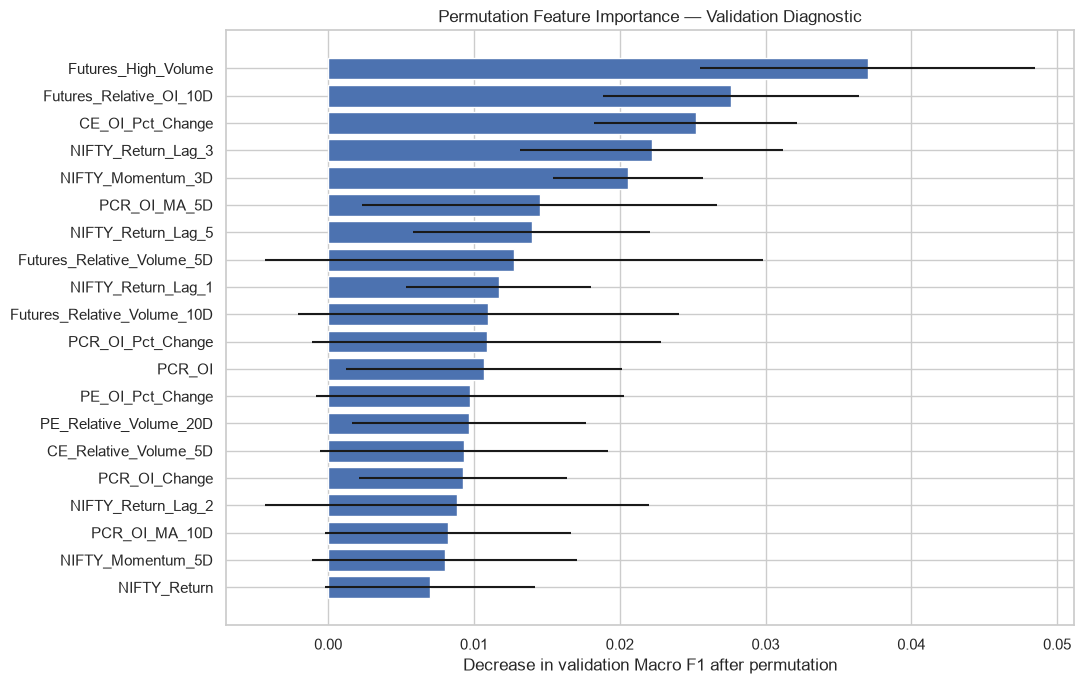

In [ ]:
# 9.1 Permutation feature importance on validation observations

permutation_result = permutation_importance(
    final_model,
    X_validation,
    y_validation,
    scoring=macro_f1_scorer,
    n_repeats=8,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

permutation_importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std,
}).sort_values("Importance_Mean", ascending=False)

display(permutation_importance_df.head(20))

plt.figure(figsize=(11, 7))

top_importance = (
    permutation_importance_df
    .head(20)
    .sort_values("Importance_Mean")
)

plt.barh(
    top_importance["Feature"],
    top_importance["Importance_Mean"],
    xerr=top_importance["Importance_Std"]
)

plt.xlabel("Decrease in validation Macro F1 after permutation")
plt.title("Permutation Feature Importance — Validation Diagnostic")
plt.tight_layout()
plt.show()

In [ ]:
# 9.2 Native model importance when the estimator exposes it

fitted_core_model = (
    final_model.named_steps["model"]
    if isinstance(final_model, Pipeline)
    else final_model
)

native_importance_df = None

if hasattr(fitted_core_model, "feature_importances_"):

    native_importance_df = pd.DataFrame({
        "Feature": feature_columns,
        "Native_Importance": fitted_core_model.feature_importances_,
    }).sort_values(
        "Native_Importance",
        ascending=False
    )

elif hasattr(fitted_core_model, "coef_"):

    coefficients = np.asarray(
        fitted_core_model.coef_
    )

    mean_absolute_coefficient = np.mean(
        np.abs(coefficients),
        axis=0
    )

    native_importance_df = pd.DataFrame({
        "Feature": feature_columns,
        "Mean_Absolute_Coefficient": mean_absolute_coefficient,
    }).sort_values(
        "Mean_Absolute_Coefficient",
        ascending=False
    )


if native_importance_df is not None:

    display(native_importance_df.head(20))

else:

    print(
        "The selected estimator does not expose native feature importance."
    )

,Feature,Native_Importance
29,Futures_Relative_OI_20D,0.0367
27,Futures_Relative_OI_5D,0.0293
39,PCR_OI_MA_5D,0.0291
8,NIFTY_Momentum_10D,0.0284
15,CE_Relative_Volume_5D,0.0280
14,Futures_Relative_Volume_20D,0.0278
31,CE_Relative_OI_10D,0.0274
6,NIFTY_Momentum_3D,0.0274
36,PCR_OI,0.0271
42,CE_PE_Volume_Ratio,0.0267


In [ ]:
# 9.4 Create a test prediction audit table

raw_test_predictions = (
    pd.Series(y_test_pred)
    .map(ENCODED_TO_RAW)
    .astype(int)
)

raw_test_actual = y_test_raw.reset_index(drop=True)

test_predictions_df = pd.DataFrame({

    "Date": test_df["Date"].reset_index(drop=True),

    "Target_Date": test_df["Target_Date"].reset_index(drop=True),

    "Actual_Direction": raw_test_actual,

    "Predicted_Direction": raw_test_predictions,

    "Actual_Label": raw_test_actual.map({
        -1: "Down",
        0: "Sideways",
        1: "Up"
    }),

    "Predicted_Label": raw_test_predictions.map({
        -1: "Down",
        0: "Sideways",
        1: "Up"
    }),

    "Correct": (
        raw_test_actual.to_numpy()
        == raw_test_predictions.to_numpy()
    ),

})


if y_test_proba is not None:

    for encoded_class, label in CLASS_NAMES.items():

        test_predictions_df[
            f"Probability_{label}"
        ] = y_test_proba[:, encoded_class]


display(
    test_predictions_df.head(15)
)

print(
    "Test correct predictions:",
    int(test_predictions_df["Correct"].sum())
)

print(
    "Test incorrect predictions:",
    int((~test_predictions_df["Correct"]).sum())
)

,Date,Target_Date,Actual_Direction,Predicted_Direction,Actual_Label,Predicted_Label,Correct,Probability_Down,Probability_Sideways,Probability_Up
0,2026-04-08,2026-04-09,-1,0,Down,Sideways,False,0.3044,0.3576,0.3380
1,2026-04-09,2026-04-10,1,-1,Up,Down,False,0.3555,0.3123,0.3321
2,2026-04-10,2026-04-13,-1,1,Down,Up,False,0.3022,0.2690,0.4288
3,2026-04-13,2026-04-15,1,-1,Up,Down,False,0.4043,0.2787,0.3170
4,2026-04-15,2026-04-16,-1,-1,Down,Down,True,0.3571,0.3484,0.2945
5,2026-04-16,2026-04-17,1,-1,Up,Down,False,0.3592,0.3291,0.3116
6,2026-04-17,2026-04-20,0,1,Sideways,Up,False,0.3243,0.3153,0.3604
7,2026-04-20,2026-04-21,1,-1,Up,Down,False,0.3502,0.3169,0.3329
8,2026-04-21,2026-04-22,-1,1,Down,Up,False,0.3629,0.2626,0.3745
9,2026-04-22,2026-04-23,-1,0,Down,Sideways,False,0.3256,0.3701,0.3043


Test correct predictions: 45
Test incorrect predictions: 72


## 10. Save Model, Predictions and Evaluation Artifacts

The final scikit-learn pipeline is saved as one artifact so that preprocessing and classification are reused together by the future FastAPI backend. Evaluation outputs and metadata are stored separately under `models/evaluation/notebook_06/`.

In [ ]:
# 10.1 Save the final model pipeline and feature list

model_path = MODEL_DIR / "nifty50_direction_pipeline.joblib"

joblib.dump(
    final_model,
    model_path
)

feature_list_path = MODEL_DIR / "nifty50_direction_features.json"

with open(feature_list_path, "w", encoding="utf-8") as f:
    json.dump(
        feature_columns,
        f,
        indent=2
    )

print("Saved model:", model_path)
print("Saved feature list:", feature_list_path)

Saved model: /home/yashraj/nifty50-FnO-eda/models/saved_models/nifty50_direction_pipeline.joblib
Saved feature list: /home/yashraj/nifty50-FnO-eda/models/saved_models/nifty50_direction_features.json


In [ ]:
# 10.2 Save evaluation tables and predictions

validation_results_df.to_csv(
    EVALUATION_DIR / "validation_model_comparison.csv"
)

cv_results_summary.to_csv(
    EVALUATION_DIR / "training_cv_summary.csv",
    index=False
)

cv_fold_summary_df.to_csv(
    EVALUATION_DIR / "purged_cv_folds.csv",
    index=False
)

test_metrics_df.to_csv(
    EVALUATION_DIR / "final_test_metrics.csv"
)

permutation_importance_df.to_csv(
    EVALUATION_DIR / "permutation_feature_importance.csv",
    index=False
)

test_predictions_df.to_parquet(
    EVALUATION_DIR / "test_predictions.parquet",
    index=False
)

test_predictions_df.to_csv(
    EVALUATION_DIR / "test_predictions.csv",
    index=False
)

if native_importance_df is not None:

    native_importance_df.to_csv(
        EVALUATION_DIR / "native_feature_importance.csv",
        index=False
    )

print("Evaluation artifacts saved to:", EVALUATION_DIR)

Evaluation artifacts saved to: /home/yashraj/nifty50-FnO-eda/models/evaluation/notebook_06


In [ ]:
# 10.3 Create a model card / reproducibility metadata file

model_card = {

    "project": "NIFTY 50 Futures and Options Market Direction Classification",

    "notebook": "06_machine_learning.ipynb",

    "selected_model": best_model_name,

    "selected_model_type": selected_model_type,

    "primary_selection_metric": "Validation Macro F1",

    "validation_metrics": {
        k: float(v)
        for k, v in validation_selected_metrics.items()
        if isinstance(
            v,
            (int, float, np.integer, np.floating)
        ) and pd.notna(v)
    },

    "final_test_metrics": {
        k: float(v)
        for k, v in test_metrics.items()
        if isinstance(
            v,
            (int, float, np.integer, np.floating)
        ) and pd.notna(v)
    },

    "target_column": "Target_Direction",

    "raw_class_mapping": {
        "-1": "Down",
        "0": "Sideways",
        "1": "Up"
    },

    "model_class_mapping": {
        "0": "Down",
        "1": "Sideways",
        "2": "Up"
    },

    "feature_count": len(feature_columns),

    "feature_columns": feature_columns,

    "training_rows": int(len(train_df)),

    "validation_rows": int(len(validation_df)),

    "test_rows": int(len(test_df)),

    "training_start": str(train_df["Date"].min().date()),

    "training_end": str(train_df["Date"].max().date()),

    "validation_start": str(validation_df["Date"].min().date()),

    "validation_end": str(validation_df["Date"].max().date()),

    "test_start": str(test_df["Date"].min().date()),

    "test_end": str(test_df["Date"].max().date()),

    "random_state": RANDOM_STATE,

    "cross_validation": "Expanding TimeSeriesSplit with Target_Date purging",

    "cross_validation_folds_used": int(len(cv_splits)),

    "preprocessing": "Median imputation inside the saved model pipeline; StandardScaler for Logistic Regression pipeline",

    "target_provenance": ml_metadata.get(
        "underlying_source",
        "See Notebook 5 ml_metadata.json"
    ),

    "target_limitation": ml_metadata.get(
        "underlying_source_limitation",
        "Target proxy limitations must be reviewed."
    ),

    "not_a_trading_recommendation": True
}


model_card_path = EVALUATION_DIR / "model_card.json"

with open(model_card_path, "w", encoding="utf-8") as f:

    json.dump(
        model_card,
        f,
        indent=2,
        default=str
    )


print("Model card saved:", model_card_path)

Model card saved: /home/yashraj/nifty50-FnO-eda/models/evaluation/notebook_06/model_card.json


In [ ]:
# 10.4 Reload model and verify inference artifact

reloaded_model = joblib.load(
    model_path
)

reloaded_predictions = reloaded_model.predict(
    X_test
)

if not np.array_equal(
    np.asarray(reloaded_predictions),
    np.asarray(y_test_pred)
):

    raise AssertionError(
        "Reloaded model predictions do not match "
        "the original final model."
    )


print("Saved model reloaded successfully.")

print(
    "Reloaded predictions match the original test predictions."
)

print(
    "Final model artifact size (MB):",
    round(
        model_path.stat().st_size / (1024 ** 2),
        2
    )
)

Saved model reloaded successfully.
Reloaded predictions match the original test predictions.
Final model artifact size (MB): 1.87


In [ ]:
# 10.5 Final experiment summary

summary = pd.DataFrame([

    {
        "Item": "Selected model",
        "Value": best_model_name
    },

    {
        "Item": "Training observations",
        "Value": len(train_df)
    },

    {
        "Item": "Validation observations",
        "Value": len(validation_df)
    },

    {
        "Item": "Test observations",
        "Value": len(test_df)
    },

    {
        "Item": "Features",
        "Value": len(feature_columns)
    },

    {
        "Item": "Purged CV folds",
        "Value": len(cv_splits)
    },

    {
        "Item": "Validation Macro F1",
        "Value": round(
            float(validation_selected_metrics["Macro_F1"]),
            4
        )
    },

    {
        "Item": "Test Macro F1",
        "Value": round(
            float(test_metrics["Macro_F1"]),
            4
        )
    },

    {
        "Item": "Test Balanced Accuracy",
        "Value": round(
            float(test_metrics["Balanced_Accuracy"]),
            4
        )
    },

    {
        "Item": "Model artifact",
        "Value": str(
            model_path.relative_to(PROJECT_ROOT)
        )
    }

])

display(summary)

print(
    "Notebook 6 training and evaluation workflow completed."
)

,Item,Value
0,Selected model,Extra Trees
1,Training observations,541
2,Validation observations,115
3,Test observations,117
4,Features,43
5,Purged CV folds,3
6,Validation Macro F1,0.3704
7,Test Macro F1,0.3224
8,Test Balanced Accuracy,0.3227
9,Model artifact,models/saved_models/nifty50_direction_pipeline...


Notebook 6 training and evaluation workflow completed.


## 11. Conclusion and Interpretation

### 11.1 Objective and approach

This notebook developed a three-class machine-learning experiment to classify the direction of the next observed trading session using engineered features derived from NIFTY 50 Futures, Call Options (CE) and Put Options (PE) data.

The target classes were Down (`-1`), Sideways (`0`) and Up (`1`). The labelled dataset contained 775 observations and 43 predictor features. The data was divided chronologically into 541 training observations, 115 validation observations and 117 test observations.

Four scikit-learn classifiers were evaluated: Logistic Regression, Random Forest, Extra Trees and Histogram-based Gradient Boosting. Dummy classifiers were used as reference baselines. Hyperparameters were searched using three expanding chronological folds with target-date purging. Model selection was based on validation Macro F1, with Balanced Accuracy used as a secondary metric.

### 11.2 Model selection results

The tuned Extra Trees classifier achieved the highest validation Macro F1:

| Model | Validation Accuracy | Validation Balanced Accuracy | Validation Macro F1 |
|---|---:|---:|---:|
| Extra Trees | 0.4696 | 0.3720 | **0.3704** |
| Random Forest | 0.4000 | 0.3580 | 0.3502 |
| Hist Gradient Boosting | 0.3739 | 0.3193 | 0.3177 |
| Dummy Stratified | 0.3826 | 0.3067 | 0.3068 |
| Logistic Regression | 0.4261 | 0.3203 | 0.2861 |
| Dummy Most Frequent | 0.4435 | 0.3333 | 0.2048 |

Extra Trees exceeded the Dummy Stratified validation Macro F1 by 0.0636 and the Dummy Most Frequent validation Macro F1 by 0.1656. It was therefore selected for the final test evaluation.

The best Extra Trees cross-validation Macro F1 was 0.3216, with a fold-to-fold standard deviation of 0.0497. Its mean training Macro F1 at the selected search configuration was 0.9984. The large difference between training and cross-validation scores indicates substantial overfitting within the training folds.

### 11.3 Final test performance

After model selection, the Extra Trees pipeline was refitted on the combined training and validation observations (656 rows) and evaluated on the untouched test partition (117 rows).

| Test metric | Result |
|---|---:|
| Accuracy | 0.3846 |
| Balanced Accuracy | 0.3227 |
| Macro Precision | 0.3223 |
| Macro Recall | 0.3227 |
| **Macro F1** | **0.3224** |
| Log Loss | 1.0262 |

The model correctly classified 45 of the 117 test observations and incorrectly classified 72. Test Macro F1 was 0.0480 lower than validation Macro F1 (0.3704), while accuracy decreased from 0.4696 to 0.3846. This decline indicates that performance did not transfer consistently from validation to the later test period.

The test classification report showed:

| Direction | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Down | 0.46 | 0.47 | 0.47 | 57 |
| Sideways | 0.15 | 0.15 | 0.15 | 13 |
| Up | 0.36 | 0.34 | 0.35 | 47 |

The model performed best on the Down class and weakest on the Sideways class. The small Sideways support (13 observations) also makes its class-level score particularly sensitive to individual predictions.

For context, Up was the most frequent training class (260 of 541 observations). A classifier that always predicted Up would achieve 47/117, or approximately 40.17%, test accuracy. The Extra Trees model's test accuracy of 38.46% was below that simple reference, although its test Macro F1 of 0.3224 was above the corresponding always-Up Macro F1 of approximately 0.1911. This illustrates why accuracy and class-balanced metrics must be considered together.

### 11.4 Feature interpretation

The native Extra Trees importance ranking assigned relatively high importance to features including:

- `Futures_Relative_OI_20D`
- `Futures_Relative_OI_5D`
- `PCR_OI_MA_5D`
- `NIFTY_Momentum_10D`
- `CE_Relative_Volume_5D`

These rankings indicate which engineered inputs the fitted tree ensemble used most when constructing its splits. They do not establish causal relationships or prove that these variables independently drive market direction.

The permutation-importance output in this run was calculated using the refitted model on validation observations that had already been included in its training data. It is therefore treated only as an in-sample descriptive diagnostic, not as an independent estimate of feature contribution.

### 11.5 Data and methodology limitations

1. **Underlying-value proxy:** The target was constructed from a derivatives-implied `Underlying Value` proxy. It is not an independently verified official NIFTY 50 spot closing-price series.
2. **Limited labelled sample:** Although the source data contains millions of derivatives records, the feature and target construction produced 775 labelled observations for this experiment. The model results should be interpreted in light of this smaller supervised-learning sample.
3. **Missing predictors:** The training partition contained 1,422 missing feature values. Median imputation was performed inside model pipelines. The missing values were not treated as evidence of zero market activity.
4. **Class imbalance:** Sideways observations represented a relatively small portion of each partition, and the model had difficulty identifying this class.
5. **Temporal variation and overfitting:** The gap between cross-validation training performance and validation performance, together with the decline from validation to test metrics, indicates overfitting and/or changes in market relationships over time.
6. **Candidate-model weighting:** In this recorded run, sample weights for Histogram-based Gradient Boosting were derived from the complete training-label distribution before cross-validation. Its cross-validation score may therefore reflect information from the class proportions of fold-validation observations. The selected Extra Trees model did not use this sample-weight path; its CV search used its estimator-level class-weight configuration.
7. **Importance interpretation:** Feature-importance rankings are model-specific and should not be interpreted as causal explanations.
8. **No trading backtest:** The experiment does not evaluate transaction costs, slippage, execution constraints, position sizing, drawdowns or risk-adjusted trading returns.
9. **Probability calibration:** Predicted class probabilities were not subjected to a separate calibration study.

### 11.6 Final conclusion

The experiment demonstrates a complete machine-learning workflow for NIFTY 50 derivatives research, including data validation, chronological partitioning, baseline comparison, purged time-series cross-validation, hyperparameter search, validation-based model selection, final test evaluation, feature-importance analysis and model-artifact export.

Among the evaluated candidates, Extra Trees achieved the strongest validation Macro F1 of 0.3704 and was selected for final evaluation. On the untouched test set, it achieved an accuracy of 0.3846, Balanced Accuracy of 0.3227 and Macro F1 of 0.3224. Its performance was strongest for Down observations and weak for Sideways observations. The test results were lower than the validation results, and the high cross-validation training score indicates overfitting.

Consequently, the experiment identifies some learnable structure in the engineered futures and options features, but the recorded evidence does **not** establish reliable next-session direction prediction. The model is best interpreted as an exploratory research classifier and a reproducible machine-learning extension to the EDA study, not as a production forecasting system or trading signal.

The final Extra Trees pipeline was saved as `nifty50_direction_pipeline.joblib`. The saved artifact was reloaded successfully, and its predictions matched those from the in-memory final model.

### References

- scikit-learn, [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)
- scikit-learn, [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
- scikit-learn, [F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
- scikit-learn, [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
